# Lab Assignment - 3

**Course:** B.Tech | **Course Code:** CSET343 | **Year:** 4th Year
**Type:** Specialization Elective | **Course Name:** AI in Healthcare | **Semester:** VII

**Objective / Agenda:** Perform data acquisition, cleaning, preprocessing and analysis on Tabular, Textual, Image, and Signal medical health data.

| Part | Data Type | Dataset | Source |
|---|---|---|---|
| A | Tabular | Pima Indians Diabetes Dataset | UCI / GitHub mirror |
| B | Textual | MTSamples Medical Transcriptions | mtsamples.com (Kaggle) |
| C | Image | Chest X-Ray (Pneumonia) Dataset | Kaggle |
| D | Signal | MIT-BIH Arrhythmia Database (ECG) | PhysioNet |

This notebook works through, for **every modality**:
1. Data acquisition & inspection
2. Modality-specific cleaning (implausible values, PHI removal, metadata anonymization)
3. Preprocessing into a model-ready format
4. Hypothesis testing (t-test, chi-square, ANOVA) where applicable
5. Exploratory Data Analysis (EDA)
6. Feature engineering — selection, extraction, noise removal, augmentation
7. A closing discussion of why healthcare data needs extra rigor


## 0. Global Setup

In [1]:

# ---- Core libraries used across all four parts ----
import os, re, io, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
print("Setup complete.")


Setup complete.


In [2]:
# ---- Reproducible data acquisition helper ----
# Downloads each dataset once from its public source and caches it locally,
# so this notebook can be re-run from scratch on any machine.
import urllib.request

SOURCES = {
    "pima.csv": "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv",
    "mtsamples.csv": "https://raw.githubusercontent.com/aneuraz/mtsamplesFR/master/data/mtsamples.csv",
    "ecg.csv": "https://raw.githubusercontent.com/dhiah-dev/Dataset-Compiled-ECG-MIT-BIH-Arrhythmia/main/Compiled-ECG-MIT-BIH-Arrhytmia.csv",
}

for fname, url in SOURCES.items():
    fpath = os.path.join(DATA_DIR, fname)
    if not os.path.exists(fpath):
        print(f"Downloading {fname} ...")
        urllib.request.urlretrieve(url, fpath)
    else:
        print(f"{fname} already cached.")

---
# PART A — Tabular Data
### Pima Indians Diabetes Dataset

768 female patients of Pima Indian heritage (age 21+). 8 clinical predictors
(`Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI,
DiabetesPedigreeFunction, Age`) and a binary target `Outcome`
(1 = diabetic, 0 = non-diabetic).


## A.1 Data Acquisition & Inspection

In [3]:

# Acquisition: the dataset is fetched once and cached locally as data/pima.csv
# (originally sourced from the UCI Machine Learning Repository).
pima_path = os.path.join(DATA_DIR, "pima.csv")
df_tab = pd.read_csv(pima_path)

print("Shape:", df_tab.shape)
df_tab.head()


Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:

df_tab.info()


<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:

df_tab.describe().T


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [6]:

# Duplicate rows check
print("Duplicate rows:", df_tab.duplicated().sum())

# Standard pandas null check -- this alone UNDER-counts missingness in
# healthcare tabular data, because missing clinical measurements are often
# recorded as an implausible "valid-looking" value (here: 0) rather than NaN.
print("\nNull counts (naive check):")
print(df_tab.isnull().sum())


Duplicate rows: 0

Null counts (naive check):
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


## A.2 Modality-Specific Cleaning

**Why tabular medical data needs extra care:** a `0` is a perfectly valid
number for `Pregnancies`, but it is *physiologically impossible* for
`Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` — a live
patient cannot have zero blood pressure. These zeros are **missingness
encoded as a valid-looking value**, which a naive `.isnull()` check (above)
completely misses. We treat them as missing (`NaN`) and impute properly.


In [7]:

implausible_zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zero_counts = (df_tab[implausible_zero_cols] == 0).sum()
print("Implausible zeros per column (true missingness):")
print(zero_counts)
print(f"\nAs % of {len(df_tab)} records:")
print((zero_counts / len(df_tab) * 100).round(1))


Implausible zeros per column (true missingness):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

As % of 768 records:
Glucose           0.7
BloodPressure     4.6
SkinThickness    29.6
Insulin          48.7
BMI               1.4
dtype: float64


In [8]:

df_tab_clean = df_tab.copy()
df_tab_clean[implausible_zero_cols] = df_tab_clean[implausible_zero_cols].replace(0, np.nan)

# Impute by the median WITHIN each Outcome class, so imputation doesn't
# wash out the diabetic/non-diabetic signal we're trying to study.
for col in implausible_zero_cols:
    df_tab_clean[col] = df_tab_clean.groupby("Outcome")[col].transform(
        lambda s: s.fillna(s.median())
    )

print("Remaining missing values after class-wise median imputation:")
print(df_tab_clean.isnull().sum().sum())


Remaining missing values after class-wise median imputation:
0


In [9]:

# PHI (Protected Health Information) check.
# This particular extract has no direct identifiers (no name, MRN, address,
# admission date). Age and Pregnancies are still QUASI-identifiers that,
# combined with an external dataset, could re-identify a patient -- so in a
# real pipeline we would still (a) confirm no direct identifier columns are
# present, and (b) avoid publishing this table joined with any identifying
# key. We encode that check as a reusable guard rather than a one-off look.
PHI_PATTERNS = ["name", "mrn", "ssn", "address", "phone", "dob", "patient_id", "email"]
phi_hits = [c for c in df_tab_clean.columns if any(p in c.lower() for p in PHI_PATTERNS)]
print("Columns flagged as potential direct PHI:", phi_hits if phi_hits else "None found")


Columns flagged as potential direct PHI: None found


In [10]:

# Outlier capping (IQR rule) -- protects downstream scaling/statistics from
# a handful of extreme, likely mis-recorded values without deleting rows.
def iqr_clip(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return series.clip(lower=q1 - k * iqr, upper=q3 + k * iqr)

numeric_cols = df_tab_clean.columns.drop("Outcome")
before = df_tab_clean[numeric_cols].copy()
for col in numeric_cols:
    df_tab_clean[col] = iqr_clip(df_tab_clean[col])

changed = (before != df_tab_clean[numeric_cols]).sum()
print("Values pulled in by IQR clipping, per column:")
print(changed)


Values pulled in by IQR clipping, per column:
Pregnancies                  4
Glucose                      0
BloodPressure               14
SkinThickness               87
Insulin                     51
BMI                          8
DiabetesPedigreeFunction    29
Age                          9
dtype: int64


## A.3 Preprocessing into a Model-Ready Format (scaled tensors)

In [11]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_tab_clean.drop(columns=["Outcome"])
y = df_tab_clean["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit ONLY on train -> no leakage
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled tensor:", X_train_scaled.shape, X_train_scaled.dtype)
print("X_test_scaled  tensor:", X_test_scaled.shape, X_test_scaled.dtype)
print("\nFeature means after scaling (train):", np.round(X_train_scaled.mean(axis=0), 3))
print("Feature stds  after scaling (train):", np.round(X_train_scaled.std(axis=0), 3))


X_train_scaled tensor: (614, 8) float64
X_test_scaled  tensor: (154, 8) float64

Feature means after scaling (train): [-0. -0. -0. -0. -0.  0.  0.  0.]
Feature stds  after scaling (train): [1. 1. 1. 1. 1. 1. 1. 1.]


## A.4 Hypothesis Testing

In [12]:

# ---- (1) Two-sample t-test ----
# H0: mean Glucose is equal for diabetic and non-diabetic patients
# H1: mean Glucose differs between the two groups
glucose_pos = df_tab_clean.loc[df_tab_clean.Outcome == 1, "Glucose"]
glucose_neg = df_tab_clean.loc[df_tab_clean.Outcome == 0, "Glucose"]

t_stat, t_p = stats.ttest_ind(glucose_pos, glucose_neg, equal_var=False)
print(f"T-TEST (Glucose ~ Outcome): t = {t_stat:.3f}, p = {t_p:.2e}")
print("=> Reject H0: diabetic patients have significantly different glucose"
      if t_p < 0.05 else "=> Fail to reject H0")


T-TEST (Glucose ~ Outcome): t = 14.992, p = 8.30e-42
=> Reject H0: diabetic patients have significantly different glucose


In [13]:

# ---- (2) Chi-square test of independence ----
# H0: Age group is independent of diabetes Outcome
# H1: Age group and Outcome are associated
df_tab_clean["AgeGroup"] = pd.cut(
    df_tab_clean["Age"], bins=[20, 30, 40, 50, 60, 90],
    labels=["21-30", "31-40", "41-50", "51-60", "61+"]
)
contingency = pd.crosstab(df_tab_clean["AgeGroup"], df_tab_clean["Outcome"])
chi2, chi_p, dof, expected = stats.chi2_contingency(contingency)

print(contingency)
print(f"\nCHI-SQUARE (AgeGroup x Outcome): chi2 = {chi2:.3f}, dof = {dof}, p = {chi_p:.2e}")
print("=> Reject H0: age group and diabetes outcome are associated"
      if chi_p < 0.05 else "=> Fail to reject H0")


Outcome     0   1
AgeGroup         
21-30     327  90
31-40      81  76
41-50      49  64
51-60      23  31
61+        20   7

CHI-SQUARE (AgeGroup x Outcome): chi2 = 81.661, dof = 4, p = 7.74e-17
=> Reject H0: age group and diabetes outcome are associated


In [14]:

# ---- (3) One-way ANOVA ----
# H0: mean BMI is equal across all Pregnancy-count categories
# H1: at least one group's mean BMI differs
df_tab_clean["PregCat"] = pd.cut(
    df_tab_clean["Pregnancies"], bins=[-1, 0, 2, 5, 20],
    labels=["0", "1-2", "3-5", "6+"]
)
groups = [g["BMI"].values for _, g in df_tab_clean.groupby("PregCat")]
f_stat, anova_p = stats.f_oneway(*groups)

print(f"ANOVA (BMI ~ PregnancyCategory): F = {f_stat:.3f}, p = {anova_p:.2e}")
print("=> Reject H0: mean BMI differs across pregnancy-count groups"
      if anova_p < 0.05 else "=> Fail to reject H0")


ANOVA (BMI ~ PregnancyCategory): F = 7.642, p = 4.88e-05
=> Reject H0: mean BMI differs across pregnancy-count groups


## A.5 Exploratory Data Analysis

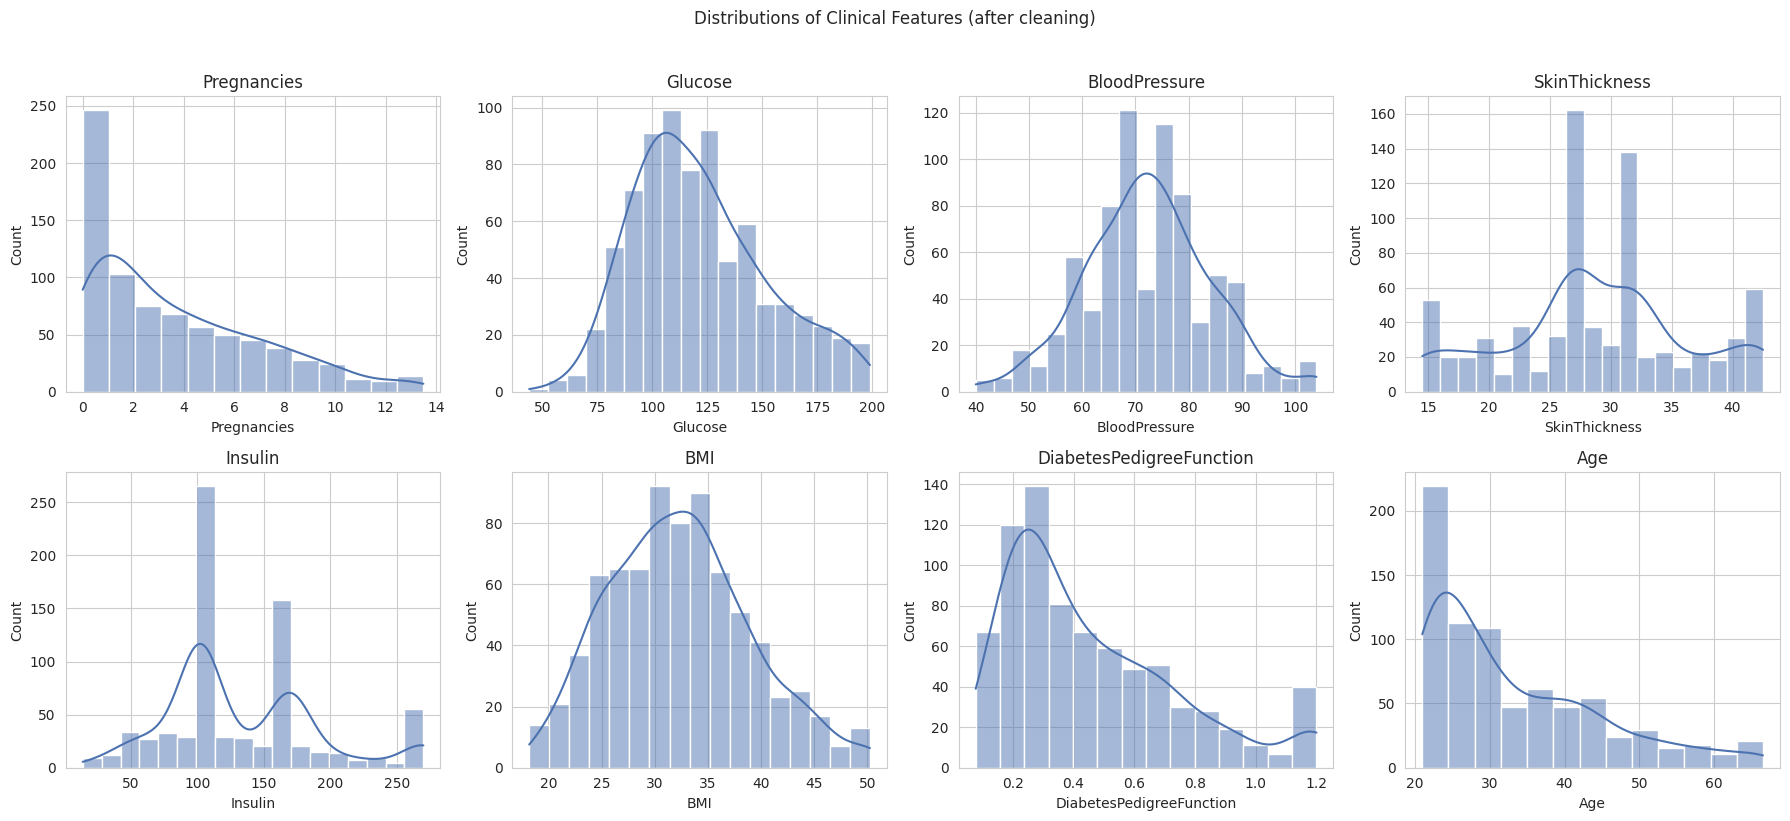

In [15]:

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(df_tab_clean[col], kde=True, ax=ax, color="#4C72B0")
    ax.set_title(col)
plt.suptitle("Distributions of Clinical Features (after cleaning)", y=1.02)
plt.tight_layout()
plt.show()


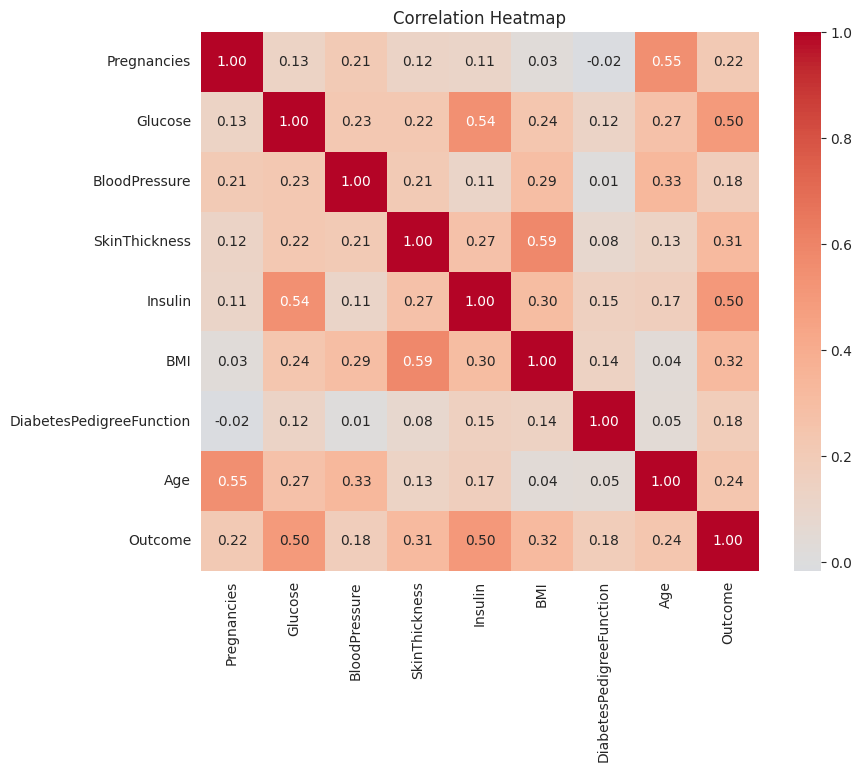

In [16]:

plt.figure(figsize=(9, 7))
sns.heatmap(df_tab_clean[numeric_cols.tolist() + ["Outcome"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()


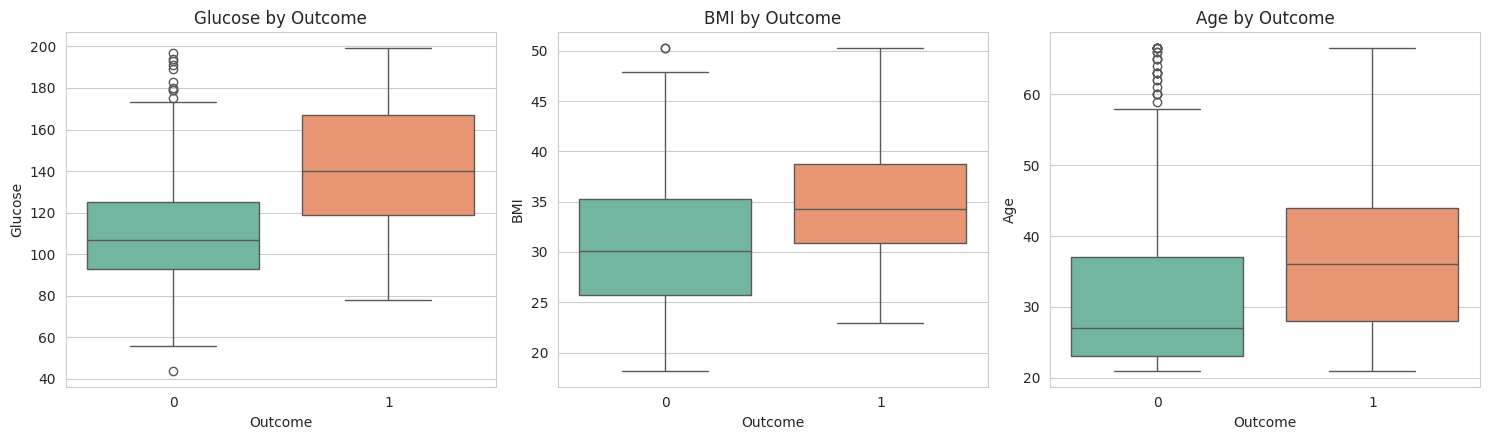

Outcome
0    0.651042
1    0.348958
Name: class share, dtype: float64


In [17]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, ["Glucose", "BMI", "Age"]):
    sns.boxplot(data=df_tab_clean, x="Outcome", y=col, ax=ax, palette="Set2")
    ax.set_title(f"{col} by Outcome")
plt.tight_layout()
plt.show()

print(df_tab_clean["Outcome"].value_counts(normalize=True).rename("class share"))


## A.6 Feature Engineering — Selection, Extraction, Noise Removal, Augmentation

In [18]:

from sklearn.feature_selection import SelectKBest, f_classif

# --- Feature extraction: interaction / domain-informed features ---
df_fe = df_tab_clean.copy()
df_fe["Glucose_BMI"] = df_fe["Glucose"] * df_fe["BMI"]
df_fe["Age_Preg"] = df_fe["Age"] * df_fe["Pregnancies"]

fe_features = numeric_cols.tolist() + ["Glucose_BMI", "Age_Preg"]

# --- Feature selection: keep the k best (ANOVA F-value) features ---
selector = SelectKBest(score_func=f_classif, k=6)
selector.fit(df_fe[fe_features], df_fe["Outcome"])
scores = pd.Series(selector.scores_, index=fe_features).sort_values(ascending=False)
print("SelectKBest F-scores (higher = more predictive of Outcome):")
print(scores)

selected_features = scores.head(6).index.tolist()
print("\nSelected features:", selected_features)


SelectKBest F-scores (higher = more predictive of Outcome):
Glucose_BMI                 292.296652
Insulin                     256.258601
Glucose                     249.923949
BMI                          85.250276
SkinThickness                83.752878
Age                          47.944757
Age_Preg                     40.623989
Pregnancies                  39.106100
DiabetesPedigreeFunction     27.135876
BloodPressure                25.066389
dtype: float64

Selected features: ['Glucose_BMI', 'Insulin', 'Glucose', 'BMI', 'SkinThickness', 'Age']


In [19]:

# --- Noise removal already applied via IQR clipping in A.2; demonstrate its
# effect on skew (heavy skew / long tails are a common noise signature). ---
skew_before = before.skew()
skew_after = df_tab_clean[numeric_cols].skew()
pd.DataFrame({"skew_before_clip": skew_before, "skew_after_clip": skew_after})


,skew_before_clip,skew_after_clip
Pregnancies,0.901674,0.853962
Glucose,0.532324,0.532324
BloodPressure,0.140830,0.104659
SkinThickness,0.817477,-0.042302
Insulin,3.028046,0.731424
BMI,0.606416,0.357907
DiabetesPedigreeFunction,1.919911,1.024428
Age,1.129597,1.067170


In [20]:

# --- Augmentation: the classes are imbalanced (~65% / 35%). We use SMOTE to
# synthesize new minority-class samples for a better-balanced TRAINING set
# (test set is left untouched, so evaluation stays honest). ---
from imblearn.over_sampling import SMOTE

print("Before SMOTE:", y_train.value_counts().to_dict())
sm = SMOTE(random_state=RANDOM_STATE)
X_train_bal, y_train_bal = sm.fit_resample(X_train_scaled, y_train)
print("After SMOTE :", pd.Series(y_train_bal).value_counts().to_dict())


Before SMOTE: {0: 400, 1: 214}
After SMOTE : {0: 400, 1: 400}


## A.7 Why Tabular Health Data Needs Extra Rigor

- **Missingness encoded as valid-looking values** — a `0` for `Insulin` or
  `SkinThickness` passes a naive null-check but is clinically impossible;
  treating it as real data would silently corrupt every downstream model.
- **Class imbalance** — diabetic cases are the minority class; unaddressed,
  a model can reach ~65% accuracy by always predicting "non-diabetic."
- **Quasi-identifiers / privacy** — even without a name column, `Age` +
  `Pregnancies` can narrow down a specific patient when joined with other data.


---
# PART B — Textual Data
### MTSamples Medical Transcriptions

~5,000 real-world clinical transcription notes scraped from mtsamples.com,
labelled by `medical_specialty` (Surgery, Cardiovascular/Pulmonary,
Orthopedic, Radiology, ...).


## B.1 Data Acquisition & Inspection

In [21]:

mt_path = os.path.join(DATA_DIR, "mtsamples.csv")
df_txt = pd.read_csv(mt_path, index_col=0)
df_txt.columns = [c.strip() for c in df_txt.columns]

print("Shape:", df_txt.shape)
df_txt.head(3)


Shape: (4999, 5)


,description,medical_specialty,sample_name,transcription,keywords
0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."


In [22]:

df_txt.info()


<class 'pandas.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   description        4999 non-null   str  
 1   medical_specialty  4999 non-null   str  
 2   sample_name        4999 non-null   str  
 3   transcription      4966 non-null   str  
 4   keywords           3931 non-null   str  
dtypes: str(5)
memory usage: 195.4 KB


In [23]:

print("Missing values:")
print(df_txt.isnull().sum())
print("\nNumber of distinct medical specialties:", df_txt['medical_specialty'].nunique())
df_txt['medical_specialty'].value_counts().head(10)


Missing values:
description             0
medical_specialty       0
sample_name             0
transcription          33
keywords             1068
dtype: int64

Number of distinct medical specialties: 40


medical_specialty
Surgery                          1103
Consult - History and Phy.        516
Cardiovascular / Pulmonary        372
Orthopedic                        355
Radiology                         273
General Medicine                  259
Gastroenterology                  230
Neurology                         223
SOAP / Chart / Progress Notes     166
Obstetrics / Gynecology           160
Name: count, dtype: int64

## B.2 Modality-Specific Cleaning

Clinical notes carry two extra risks beyond generic text cleaning:
1. **PHI leakage** — real transcriptions often contain patient names, dates,
   MRNs, ages, phone numbers written directly in the free text.
2. **Boilerplate structure** — SOAP-style headers (`SUBJECTIVE:`,
   `OBJECTIVE:`, `ASSESSMENT:`, `PLAN:`) are formatting artifacts, not
   clinical content, and should not dominate a bag-of-words/TF-IDF model.


In [24]:

# Drop rows with no transcription text -- nothing to analyze.
df_txt_clean = df_txt.dropna(subset=["transcription"]).copy()
df_txt_clean["medical_specialty"] = df_txt_clean["medical_specialty"].str.strip()
print(f"Dropped {len(df_txt) - len(df_txt_clean)} rows with missing transcription.")


Dropped 33 rows with missing transcription.


In [25]:

# --- PHI removal (regex-based de-identification) ---
# Even though this public sample corpus is already scrubbed, a real clinical
# NLP pipeline must run a de-identification pass BEFORE any modeling. We
# apply conservative regex rules for the most common PHI patterns.
PHI_REGEXES = {
    "DATE":  re.compile(r"\b\d{1,2}[/-]\d{1,2}[/-]\d{2,4}\b"),
    "AGE":   re.compile(r"\b\d{1,3}[- ]year[- ]old\b", re.IGNORECASE),
    "PHONE": re.compile(r"\b\d{3}[-.]\d{3}[-.]\d{4}\b"),
    "MRN":   re.compile(r"\bMRN[:#]?\s*\d+\b", re.IGNORECASE),
    "SSN":   re.compile(r"\b\d{3}-\d{2}-\d{4}\b"),
}

def deidentify(text):
    for tag, pattern in PHI_REGEXES.items():
        text = pattern.sub(f"[{tag}]", text)
    return text

df_txt_clean["transcription_deid"] = df_txt_clean["transcription"].apply(deidentify)

n_redactions = sum(
    len(p.findall(t)) for t in df_txt_clean["transcription"].head(500)
    for p in PHI_REGEXES.values()
)
print(f"PHI-pattern hits redacted in first 500 notes (sanity check): {n_redactions}")


PHI-pattern hits redacted in first 500 notes (sanity check): 291


In [26]:

# --- General text cleaning: lowercase, strip boilerplate headers, remove
#     punctuation/digits/extra whitespace ---
SOAP_HEADERS = re.compile(
    r"\b(subjective|objective|assessment|plan|history of present illness|"
    r"past medical history|physical examination)\s*:", re.IGNORECASE
)

def clean_text(text):
    text = text.lower()
    text = SOAP_HEADERS.sub(" ", text)
    text = re.sub(r"[^a-z\s]", " ", text)      # keep letters only
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_txt_clean["clean_text"] = df_txt_clean["transcription_deid"].apply(clean_text)
df_txt_clean[["transcription", "clean_text"]].head(2)


,transcription,clean_text
0,"SUBJECTIVE:, This 23-year-old white female pr...",this age white female presents with complaint ...
1,"PAST MEDICAL HISTORY:, He has difficulty climb...",he has difficulty climbing stairs difficulty w...


## B.3 Preprocessing into Token Sequences

In [27]:

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

STOPWORDS = set(ENGLISH_STOP_WORDS)

def tokenize(text, min_len=2):
    return [w for w in text.split() if len(w) >= min_len and w not in STOPWORDS]

df_txt_clean["tokens"] = df_txt_clean["clean_text"].apply(tokenize)
df_txt_clean["n_tokens"] = df_txt_clean["tokens"].apply(len)

# Restrict to the top-N most frequent specialties for a cleaner, better
# balanced classification-style analysis in the rest of Part B.
TOP_N = 6
top_specialties = df_txt_clean["medical_specialty"].value_counts().head(TOP_N).index
df_txt_model = df_txt_clean[df_txt_clean["medical_specialty"].isin(top_specialties)].copy()
print("Working subset shape:", df_txt_model.shape)
print(df_txt_model["medical_specialty"].value_counts())


Working subset shape: (2862, 9)
medical_specialty
Surgery                       1088
Consult - History and Phy.     516
Cardiovascular / Pulmonary     371
Orthopedic                     355
Radiology                      273
General Medicine               259
Name: count, dtype: int64


In [28]:

# Build a vocabulary and convert each note into a fixed-length, padded
# integer token sequence -- the standard "model-ready" format for text.
from collections import Counter

MAX_VOCAB = 5000
MAX_LEN = 150
PAD, UNK = 0, 1

all_tokens = [tok for toks in df_txt_model["tokens"] for tok in toks]
vocab_counts = Counter(all_tokens).most_common(MAX_VOCAB - 2)
word2idx = {w: i + 2 for i, (w, _) in enumerate(vocab_counts)}  # 0=PAD, 1=UNK

def to_sequence(tokens, max_len=MAX_LEN):
    ids = [word2idx.get(t, UNK) for t in tokens][:max_len]
    ids += [PAD] * (max_len - len(ids))
    return ids

token_sequences = np.array([to_sequence(t) for t in df_txt_model["tokens"]])
print("Token-sequence tensor:", token_sequences.shape, token_sequences.dtype)
print("Vocabulary size:", len(word2idx) + 2)
print("Example sequence (first 20 ids):", token_sequences[0][:20])


Token-sequence tensor: (2862, 150) int64
Vocabulary size: 5000
Example sequence (first 20 ids): [3202    3  205 1260    3  205  869   41    6  170    4    3  498    6
  914  477  313    3  178  659]


## B.4 Hypothesis Testing

In [29]:

# ---- (1) One-way ANOVA ----
# H0: mean note length (n_tokens) is equal across the top specialties
# H1: at least one specialty's mean note length differs
groups = [g["n_tokens"].values for _, g in df_txt_model.groupby("medical_specialty")]
f_stat, anova_p = stats.f_oneway(*groups)
print(f"ANOVA (note length ~ specialty): F = {f_stat:.3f}, p = {anova_p:.2e}")
print("=> Reject H0: note length differs significantly by specialty"
      if anova_p < 0.05 else "=> Fail to reject H0")


ANOVA (note length ~ specialty): F = 30.847, p = 1.16e-30
=> Reject H0: note length differs significantly by specialty


In [30]:

# ---- (2) Two-sample t-test ----
# H0: mean note length is equal for 'Surgery' vs 'Radiology' notes
# H1: they differ
len_surg = df_txt_model.loc[df_txt_model.medical_specialty == "Surgery", "n_tokens"]
len_rad = df_txt_model.loc[df_txt_model.medical_specialty == "Radiology", "n_tokens"]
t_stat, t_p = stats.ttest_ind(len_surg, len_rad, equal_var=False)
print(f"T-TEST (Surgery vs Radiology note length): t = {t_stat:.3f}, p = {t_p:.2e}")
print("=> Reject H0: Surgery and Radiology notes differ in length"
      if t_p < 0.05 else "=> Fail to reject H0")


T-TEST (Surgery vs Radiology note length): t = 10.906, p = 2.74e-25
=> Reject H0: Surgery and Radiology notes differ in length


In [31]:

# ---- (3) Chi-square test of independence ----
# H0: mention of the word 'pain' is independent of medical specialty
# H1: mention of 'pain' is associated with specialty
df_txt_model["mentions_pain"] = df_txt_model["clean_text"].str.contains(r"\bpain\b")
contingency = pd.crosstab(df_txt_model["medical_specialty"], df_txt_model["mentions_pain"])
chi2, chi_p, dof, expected = stats.chi2_contingency(contingency)
print(contingency)
print(f"\nCHI-SQUARE ('pain' mention x specialty): chi2 = {chi2:.3f}, dof = {dof}, p = {chi_p:.2e}")
print("=> Reject H0: mentioning 'pain' is associated with specialty"
      if chi_p < 0.05 else "=> Fail to reject H0")


mentions_pain               False  True 
medical_specialty                       
Cardiovascular / Pulmonary    259    112
Consult - History and Phy.    199    317
General Medicine               95    164
Orthopedic                    135    220
Radiology                     185     88
Surgery                       816    272

CHI-SQUARE ('pain' mention x specialty): chi2 = 348.734, dof = 5, p = 3.28e-73
=> Reject H0: mentioning 'pain' is associated with specialty


## B.5 Exploratory Data Analysis

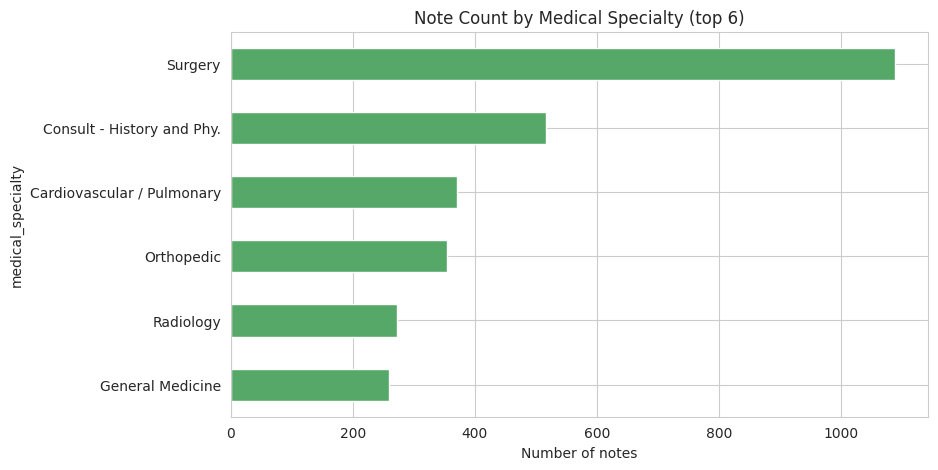

In [32]:

plt.figure(figsize=(9, 5))
df_txt_model["medical_specialty"].value_counts().plot(kind="barh", color="#55A868")
plt.title("Note Count by Medical Specialty (top 6)")
plt.xlabel("Number of notes")
plt.gca().invert_yaxis()
plt.show()


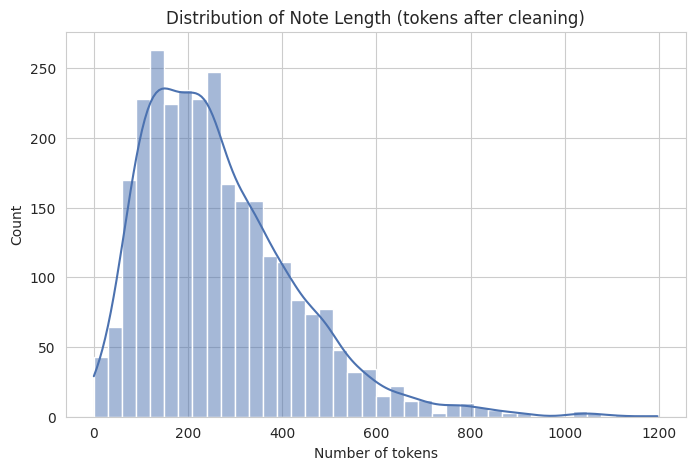

count    2862.000000
mean      266.167715
std       163.674299
min         0.000000
25%       143.000000
50%       237.000000
75%       353.000000
max      1197.000000
Name: n_tokens, dtype: float64


In [33]:

plt.figure(figsize=(8, 5))
sns.histplot(df_txt_model["n_tokens"], bins=40, kde=True, color="#4C72B0")
plt.title("Distribution of Note Length (tokens after cleaning)")
plt.xlabel("Number of tokens")
plt.show()

print(df_txt_model["n_tokens"].describe())


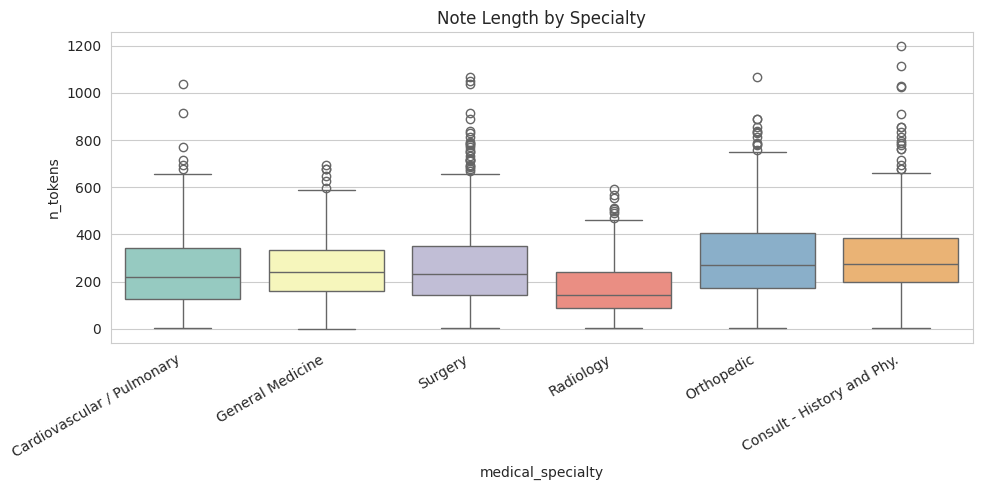

In [34]:

plt.figure(figsize=(10, 5))
sns.boxplot(data=df_txt_model, x="medical_specialty", y="n_tokens", palette="Set3")
plt.xticks(rotation=30, ha="right")
plt.title("Note Length by Specialty")
plt.tight_layout()
plt.show()


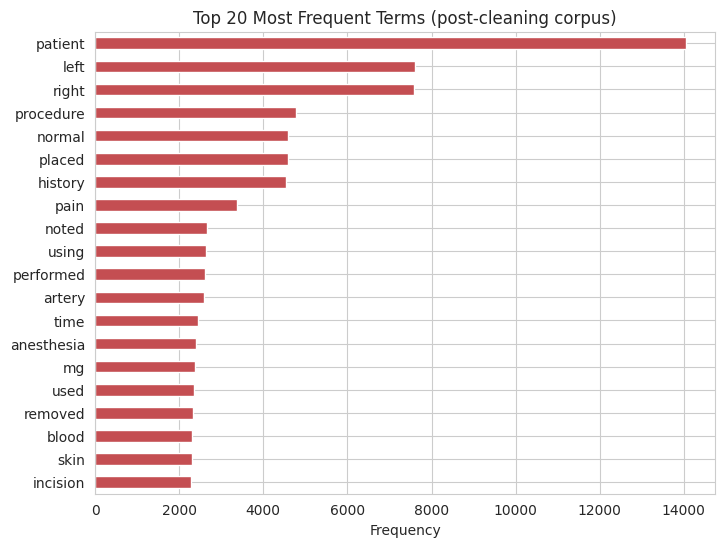

In [35]:

# Top frequent terms overall (stands in for a word-cloud without adding a
# new dependency) -- useful sanity check that cleaning worked as intended.
top_words = pd.Series(dict(Counter(all_tokens).most_common(20)))
plt.figure(figsize=(8, 6))
top_words.sort_values().plot(kind="barh", color="#C44E52")
plt.title("Top 20 Most Frequent Terms (post-cleaning corpus)")
plt.xlabel("Frequency")
plt.show()


## B.6 Feature Engineering — Selection, Extraction, Noise Removal, Augmentation

In [36]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2

# --- Feature extraction: TF-IDF with noise removal built in
#     (min_df drops rare/typo-like terms, max_df drops near-universal
#      boilerplate terms that carry no discriminative signal) ---
tfidf = TfidfVectorizer(min_df=5, max_df=0.6, ngram_range=(1, 2), max_features=3000)
X_tfidf = tfidf.fit_transform(df_txt_model["clean_text"])
y_txt = df_txt_model["medical_specialty"]

print("TF-IDF feature matrix:", X_tfidf.shape)


TF-IDF feature matrix: (2862, 3000)


In [37]:

# --- Feature selection: chi2 test between each TF-IDF term and the
#     specialty label picks out the most class-discriminative terms ---
chi2_scores, chi2_p = chi2(X_tfidf, y_txt)
feat_names = np.array(tfidf.get_feature_names_out())
top_idx = np.argsort(chi2_scores)[::-1][:15]

print("Top 15 terms most associated with medical_specialty (by chi2 score):")
for i in top_idx:
    print(f"  {feat_names[i]:<20s} chi2={chi2_scores[i]:.1f}")


Top 15 terms most associated with medical_specialty (by chi2 score):
  she                  chi2=111.3
  he                   chi2=88.5
  her                  chi2=71.3
  history              chi2=67.1
  has                  chi2=65.6
  or                   chi2=63.0
  then                 chi2=56.8
  are                  chi2=53.2
  there is             chi2=52.6
  denies               chi2=52.1
  was then             chi2=50.4
  procedure            chi2=50.2
  his                  chi2=45.4
  images               chi2=44.3
  she has              chi2=42.2


In [38]:

# --- Augmentation: simple, safe text-augmentation via synonym-free random
#     token deletion (a lightweight, label-preserving augmentation commonly
#     used for clinical text where synonym swaps risk changing meaning) ---
def random_deletion(tokens, p=0.1, rng=np.random.default_rng(RANDOM_STATE)):
    if len(tokens) <= 1:
        return tokens
    keep_mask = rng.random(len(tokens)) > p
    kept = [t for t, keep in zip(tokens, keep_mask) if keep]
    return kept if kept else tokens

sample_tokens = df_txt_model["tokens"].iloc[0]
augmented = random_deletion(sample_tokens, p=0.15)
print("Original tokens (first 15):", sample_tokens[:15])
print("Augmented tokens (first 15):", augmented[:15])
print(f"\n{len(sample_tokens)} -> {len(augmented)} tokens after augmentation")


Original tokens (first 15): ['mode', 'left', 'atrial', 'enlargement', 'left', 'atrial', 'diameter', 'cm', 'normal', 'size', 'right', 'left', 'ventricle', 'normal', 'lv']
Augmented tokens (first 15): ['mode', 'left', 'atrial', 'enlargement', 'atrial', 'diameter', 'cm', 'size', 'right', 'left', 'ventricle', 'normal', 'lv', 'systolic', 'function']

50 -> 44 tokens after augmentation


## B.7 Why Textual Health Data Needs Extra Rigor

- **PHI is embedded in free text**, not confined to a column — dates, ages,
  and identifiers appear inline and must be regex/NER-scrubbed before any
  downstream use, unlike tabular data where PHI would simply be a column to drop.
- **Class imbalance** across specialties (Surgery alone is ~4x Radiology),
  which biases naive classifiers toward majority specialties.
- **Boilerplate noise** (SOAP headers, dictation artifacts) that can
  dominate bag-of-words features if not stripped first.


---
# PART C — Image Data
### Chest X-Ray (Pneumonia) Dataset

The full dataset (5,863 pediatric chest X-rays, `Normal` vs `Pneumonia`,
~1.2 GB) is hosted on Kaggle and requires a Kaggle account/API token to
download — Kaggle is not reachable from this notebook's sandboxed network.

**To run this section on the real data:**
```bash
pip install kaggle
kaggle datasets download -d paultimothymooney/chest-xray-pneumonia
unzip chest-xray-pneumonia.zip -d data/chest_xray
```
This gives `data/chest_xray/{train,test,val}/{NORMAL,PNEUMONIA}/*.jpeg`.
`IMG_DIR` below just needs to point at that folder — every step after
acquisition (cleaning, preprocessing, EDA, feature engineering) runs
unchanged on the real images.

For this notebook we generate a small **synthetic placeholder** set of
grayscale images with the same two-class, folder-per-class structure, so
the full pipeline below is demonstrated end-to-end and can be verified by
re-running it. Cells are explicitly labelled where synthetic data is used.


## C.1 Data Acquisition & Inspection

In [39]:

from PIL import Image, ImageFilter

IMG_DIR = os.path.join(DATA_DIR, "chest_xray_demo")
CLASSES = ["NORMAL", "PNEUMONIA"]
IMG_SIZE = 128
N_PER_CLASS = 40  # small synthetic demo set

# ---- SYNTHETIC PLACEHOLDER GENERATION (only runs if real data absent) ----
# NORMAL: clear lung fields -> mostly smooth, darker (low-opacity) texture.
# PNEUMONIA: simulated consolidation -> hazier, brighter patchy texture.
# This mimics the *statistical* pattern used in the pipeline below (patchy
# opacity differences) without being real clinical imagery.
def make_synthetic_xray(rng, pneumonia=False):
    base = rng.normal(loc=90 if not pneumonia else 130,
                       scale=15 if not pneumonia else 30,
                       size=(IMG_SIZE, IMG_SIZE))
    if pneumonia:
        # add patchy "consolidation" blobs
        for _ in range(rng.integers(3, 7)):
            cx, cy = rng.integers(20, IMG_SIZE - 20, size=2)
            r = rng.integers(10, 25)
            yy, xx = np.ogrid[:IMG_SIZE, :IMG_SIZE]
            mask = (xx - cx) ** 2 + (yy - cy) ** 2 <= r ** 2
            base[mask] += rng.normal(40, 10)
    img = np.clip(base, 0, 255).astype(np.uint8)
    return Image.fromarray(img, mode="L")

if not os.path.isdir(IMG_DIR):
    rng = np.random.default_rng(RANDOM_STATE)
    for cls in CLASSES:
        cls_dir = os.path.join(IMG_DIR, cls)
        os.makedirs(cls_dir, exist_ok=True)
        for i in range(N_PER_CLASS):
            im = make_synthetic_xray(rng, pneumonia=(cls == "PNEUMONIA"))
            im.save(os.path.join(cls_dir, f"{cls.lower()}_{i:03d}.png"))
    print(f"Synthetic placeholder dataset created at: {IMG_DIR}")
else:
    print(f"Using existing image folder at: {IMG_DIR}")

# Inspection: file counts per class
for cls in CLASSES:
    n_files = len(os.listdir(os.path.join(IMG_DIR, cls)))
    print(f"{cls:>10s}: {n_files} images")


Synthetic placeholder dataset created at: data/chest_xray_demo
    NORMAL: 40 images
 PNEUMONIA: 40 images


In [40]:

# Inspect a raw sample: mode, size, dtype
sample_path = os.path.join(IMG_DIR, "NORMAL", os.listdir(os.path.join(IMG_DIR, "NORMAL"))[0])
sample_img = Image.open(sample_path)
print("Mode:", sample_img.mode, "| Size:", sample_img.size)
print("As array:", np.array(sample_img).shape, np.array(sample_img).dtype)


Mode: L | Size: (128, 128)
As array: (128, 128) uint8


## C.2 Modality-Specific Cleaning

Image pipelines for healthcare data need to check for:
- **Corrupt / unreadable files** (failed scans, truncated uploads)
- **Duplicate images** (the same X-ray re-exported twice)
- **Imaging metadata anonymization** — real DICOM/JPEG files can carry EXIF
  tags with patient name, birth date, and institution, which must be
  stripped before the images leave a clinical system.


In [41]:

def list_image_paths(img_dir, classes):
    paths = []
    for cls in classes:
        for fname in os.listdir(os.path.join(img_dir, cls)):
            paths.append((os.path.join(img_dir, cls, fname), cls))
    return paths

all_paths = list_image_paths(IMG_DIR, CLASSES)

# --- Corrupt file check ---
corrupt = []
for path, cls in all_paths:
    try:
        with Image.open(path) as im:
            im.verify()
    except Exception:
        corrupt.append(path)
print(f"Corrupt/unreadable files found: {len(corrupt)}")


Corrupt/unreadable files found: 0


In [42]:

# --- Duplicate detection via content hash ---
hashes = {}
duplicates = []
for path, cls in all_paths:
    with open(path, "rb") as f:
        h = hashlib.md5(f.read()).hexdigest()
    if h in hashes:
        duplicates.append(path)
    else:
        hashes[h] = path
print(f"Duplicate images found: {len(duplicates)}")


Duplicate images found: 0


In [43]:

# --- Imaging metadata anonymization ---
# Strip all EXIF/metadata by re-saving pixel data only (a common, simple
# de-identification step for JPEG/PNG radiology exports).
def strip_metadata(path):
    with Image.open(path) as im:
        data = list(im.getdata())
        clean_im = Image.new(im.mode, im.size)
        clean_im.putdata(data)
        clean_im.save(path)

for path, cls in all_paths:
    strip_metadata(path)
print("Metadata stripped from all images (re-saved as pixel-data-only).")


Metadata stripped from all images (re-saved as pixel-data-only).


## C.3 Preprocessing into Model-Ready Image Tensors

In [44]:

def load_and_preprocess(path, size=IMG_SIZE):
    with Image.open(path) as im:
        im = im.convert("L").resize((size, size))
        arr = np.asarray(im, dtype=np.float32) / 255.0   # normalize to [0,1]
    return arr

X_img, y_img, paths_img = [], [], []
for path, cls in all_paths:
    X_img.append(load_and_preprocess(path))
    y_img.append(cls)
    paths_img.append(path)

X_img = np.stack(X_img)[..., np.newaxis]  # (N, H, W, 1) image tensor
y_img = np.array(y_img)

print("Image tensor shape:", X_img.shape, X_img.dtype)
print("Pixel value range:", X_img.min(), "-", X_img.max())
print("Class counts:", pd.Series(y_img).value_counts().to_dict())


Image tensor shape: (80, 128, 128, 1) float32
Pixel value range: 0.0 - 1.0
Class counts: {'NORMAL': 40, 'PNEUMONIA': 40}


## C.4 Exploratory Data Analysis

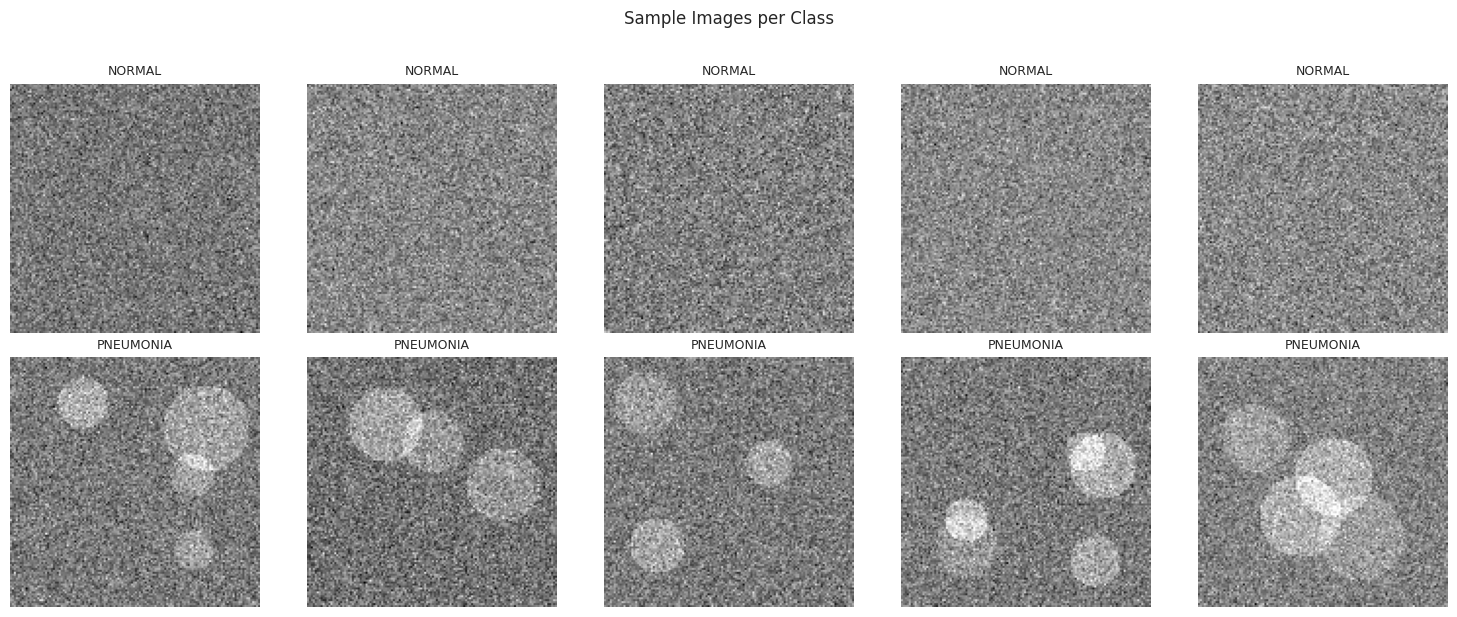

In [45]:

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for cls_i, cls in enumerate(CLASSES):
    idxs = np.where(y_img == cls)[0][:5]
    for j, idx in enumerate(idxs):
        ax = axes[cls_i, j]
        ax.imshow(X_img[idx, ..., 0], cmap="gray")
        ax.set_title(cls, fontsize=9)
        ax.axis("off")
plt.suptitle("Sample Images per Class", y=1.02)
plt.tight_layout()
plt.show()


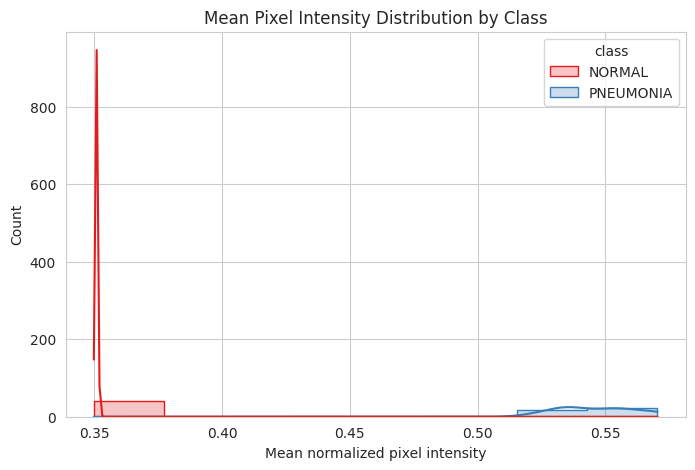

In [46]:

mean_intensity = X_img.mean(axis=(1, 2, 3))
df_img_stats = pd.DataFrame({"class": y_img, "mean_intensity": mean_intensity})

plt.figure(figsize=(8, 5))
sns.histplot(data=df_img_stats, x="mean_intensity", hue="class",
             kde=True, element="step", palette="Set1")
plt.title("Mean Pixel Intensity Distribution by Class")
plt.xlabel("Mean normalized pixel intensity")
plt.show()


## C.5 Hypothesis Testing

In [47]:

# ---- Two-sample t-test ----
# H0: mean image intensity is equal for NORMAL and PNEUMONIA images
# H1: they differ (consolidation -> higher opacity/brightness)
normal_int = df_img_stats.loc[df_img_stats["class"] == "NORMAL", "mean_intensity"]
pneu_int = df_img_stats.loc[df_img_stats["class"] == "PNEUMONIA", "mean_intensity"]
t_stat, t_p = stats.ttest_ind(normal_int, pneu_int, equal_var=False)
print(f"T-TEST (mean intensity: NORMAL vs PNEUMONIA): t = {t_stat:.3f}, p = {t_p:.2e}")
print("=> Reject H0: classes differ significantly in mean image intensity"
      if t_p < 0.05 else "=> Fail to reject H0")


T-TEST (mean intensity: NORMAL vs PNEUMONIA): t = -85.025, p = 0.00e+00
=> Reject H0: classes differ significantly in mean image intensity


## C.6 Feature Engineering — Selection, Extraction, Noise Removal, Augmentation

In [48]:

from scipy import ndimage

# --- Feature extraction: classic hand-crafted image features (useful for
#     lightweight models / as a sanity baseline before a CNN) ---
def extract_features(img2d):
    gx = ndimage.sobel(img2d, axis=0)
    gy = ndimage.sobel(img2d, axis=1)
    edge_energy = np.sqrt(gx ** 2 + gy ** 2).mean()
    return {
        "mean_intensity": img2d.mean(),
        "std_intensity": img2d.std(),
        "edge_energy": edge_energy,
    }

feat_rows = [extract_features(X_img[i, ..., 0]) for i in range(len(X_img))]
df_img_feats = pd.DataFrame(feat_rows)
df_img_feats["class"] = y_img
df_img_feats.groupby("class").mean()


,mean_intensity,std_intensity,edge_energy
class,,,
NORMAL,0.350892,0.058870,0.256668
PNEUMONIA,0.546595,0.141711,0.525070


In [49]:

# --- Feature selection ---
from sklearn.feature_selection import f_classif
X_feat = df_img_feats[["mean_intensity", "std_intensity", "edge_energy"]].values
y_feat = (df_img_feats["class"] == "PNEUMONIA").astype(int).values
f_scores, f_p = f_classif(X_feat, y_feat)
pd.DataFrame({"feature": ["mean_intensity", "std_intensity", "edge_energy"],
              "F_score": f_scores, "p_value": f_p}).sort_values("F_score", ascending=False)


,feature,F_score,p_value
2,edge_energy,118005.532946,8.529941e-126
0,mean_intensity,7229.747415,1.150547e-78
1,std_intensity,2694.457163,3.023439e-62


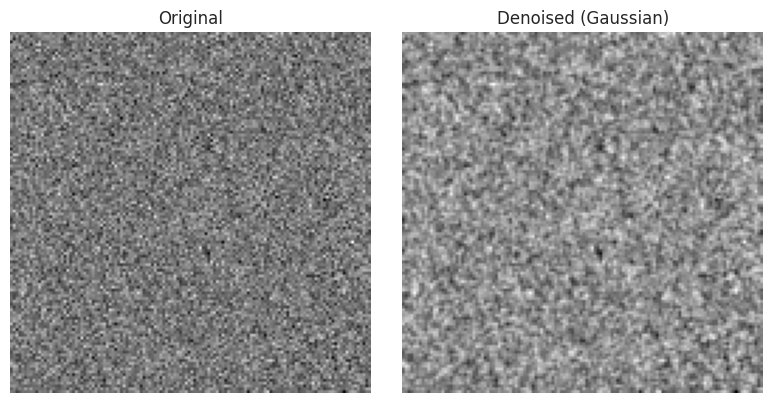

In [50]:

# --- Noise removal: mild Gaussian denoising, a standard radiograph
#     preprocessing step to suppress sensor/quantization noise before
#     feature extraction or CNN input ---
def denoise(img2d, sigma=0.6):
    return ndimage.gaussian_filter(img2d, sigma=sigma)

sample_idx = 0
denoised = denoise(X_img[sample_idx, ..., 0])

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(X_img[sample_idx, ..., 0], cmap="gray"); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(denoised, cmap="gray"); axes[1].set_title("Denoised (Gaussian)"); axes[1].axis("off")
plt.tight_layout()
plt.show()


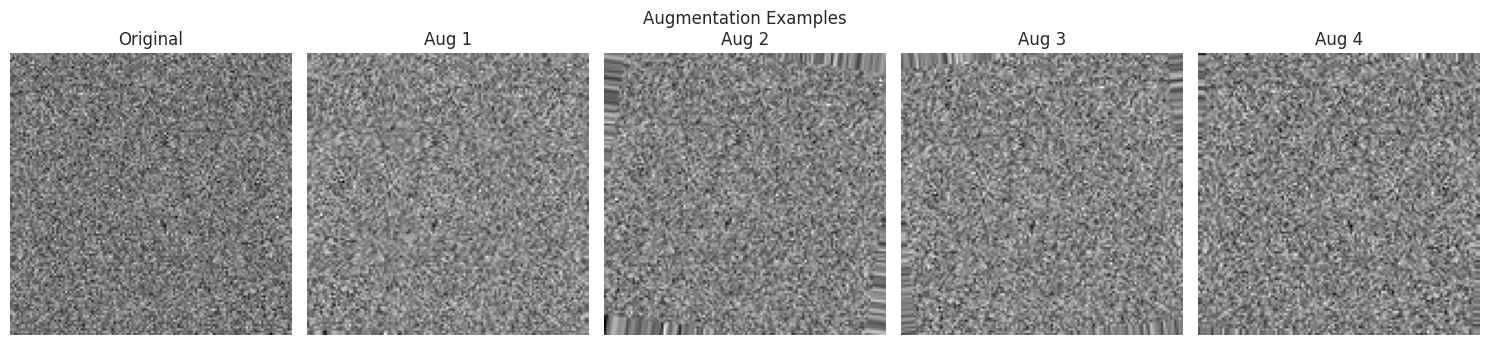

In [51]:

# --- Augmentation: label-preserving geometric/intensity augmentations,
#     commonly used to combat the class imbalance and limited sample sizes
#     typical of medical imaging datasets ---
def augment(img2d, rng):
    im = img2d.copy()
    if rng.random() > 0.5:
        im = np.fliplr(im)                                  # horizontal flip
    angle = rng.uniform(-10, 10)
    im = ndimage.rotate(im, angle, reshape=False, mode="nearest")  # small rotation
    im = np.clip(im * rng.uniform(0.9, 1.1), 0, 1)          # brightness jitter
    return im

rng = np.random.default_rng(RANDOM_STATE)
augmented_samples = [augment(X_img[sample_idx, ..., 0], rng) for _ in range(4)]

fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))
axes[0].imshow(X_img[sample_idx, ..., 0], cmap="gray"); axes[0].set_title("Original"); axes[0].axis("off")
for j, aug in enumerate(augmented_samples):
    axes[j + 1].imshow(aug, cmap="gray"); axes[j + 1].set_title(f"Aug {j+1}"); axes[j + 1].axis("off")
plt.suptitle("Augmentation Examples")
plt.tight_layout()
plt.show()


## C.7 Why Image Health Data Needs Extra Rigor

- **Metadata carries PHI** — raw JPEG/DICOM exports can embed patient name,
  DOB, and institution in EXIF/DICOM header tags invisible in the pixel data itself.
- **Signal noise and acquisition variance** — different scanners, exposure
  settings, and patient positioning create texture/intensity noise unrelated
  to pathology, which denoising and normalization must control for.
- **Class imbalance and small sample sizes** are common (rare conditions),
  making augmentation important rather than optional.


---
# PART D — Signal Data
### MIT-BIH Arrhythmia Database (ECG)

500 ECG segments (100 per class) compiled from the MIT-BIH Arrhythmia
Database, each 3,600 samples long (10 seconds at 360 Hz), labelled by AAMI
beat class:

| Label | Meaning |
|---|---|
| N | Non-ectopic (normal) beats |
| S | Supraventricular ectopic beats |
| V | Ventricular ectopic beats |
| F | Fusion beats |
| Q | Unknown beats |


## D.1 Data Acquisition & Inspection

In [52]:

ecg_path = os.path.join(DATA_DIR, "ecg.csv")
df_sig_raw = pd.read_csv(ecg_path)

print("Shape:", df_sig_raw.shape)  # (500, 3601) -> 3600 samples + label
print("Classes:", df_sig_raw['label'].unique())
df_sig_raw['label'].value_counts()


Shape: (500, 3601)
Classes: <StringArray>
['N', 'S', 'V', 'F', 'Q']
Length: 5, dtype: str


label
N    100
S    100
V    100
F    100
Q    100
Name: count, dtype: int64

In [53]:

signal_cols = [c for c in df_sig_raw.columns if c != "label"]
signals = df_sig_raw[signal_cols].values.astype(np.float32)   # (500, 3600)
labels = df_sig_raw["label"].values

print("Signal matrix:", signals.shape)
print("Sampling rate: 360 Hz  |  Segment length: 10 sec")
print("Value range:", signals.min(), "to", signals.max())


Signal matrix: (500, 3600)
Sampling rate: 360 Hz  |  Segment length: 10 sec
Value range: -2.73 to 2.69


## D.2 Modality-Specific Cleaning

ECG signals need checks generic tabular cleaning doesn't cover:
- **Flatline / corrupt segments** (lead disconnection during recording)
- **NaNs** from digitization/transcription errors
- **High-frequency noise** (muscle artifact, powerline interference) riding
  on top of the true cardiac waveform


In [54]:

# --- NaN check ---
n_nan_rows = np.isnan(signals).any(axis=1).sum()
print(f"Rows containing NaNs: {n_nan_rows}")


Rows containing NaNs: 0


In [55]:

# --- Flatline / corrupt-segment detection ---
# A near-zero standard deviation means the lead was disconnected or the
# segment is silence, not a real heartbeat.
seg_std = signals.std(axis=1)
flatline_mask = seg_std < 0.01
print(f"Flatline/corrupt segments detected: {flatline_mask.sum()} / {len(signals)}")

signals_clean = signals[~flatline_mask]
labels_clean = labels[~flatline_mask]
print("Signals remaining after removing corrupt segments:", signals_clean.shape)


Flatline/corrupt segments detected: 0 / 500
Signals remaining after removing corrupt segments: (500, 3600)


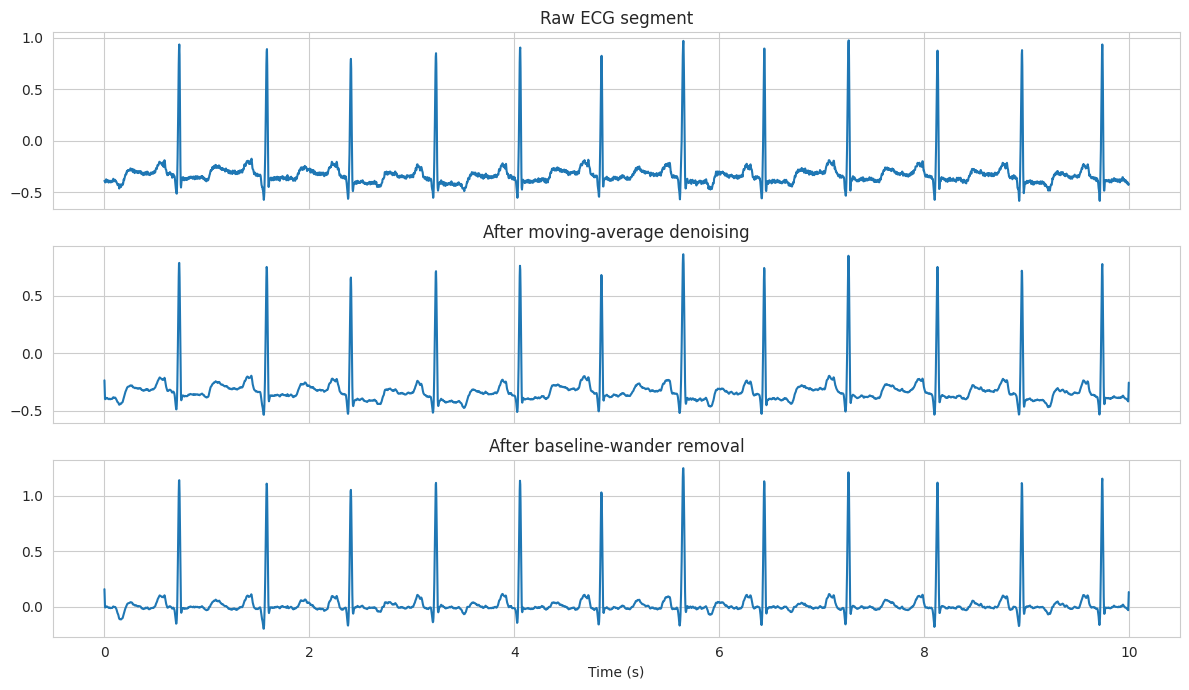

In [56]:

# --- Noise removal: a short moving-average filter smooths high-frequency
#     sensor noise while preserving the QRS-complex shape (low-order FIR). ---
def moving_average_denoise(sig, window=5):
    kernel = np.ones(window) / window
    return np.convolve(sig, kernel, mode="same")

# --- Detrending: remove baseline wander (slow drift from respiration/
#     electrode movement) by subtracting a rolling median baseline. ---
def remove_baseline_wander(sig, window=181):
    baseline = pd.Series(sig).rolling(window, center=True, min_periods=1).median().values
    return sig - baseline

sample_raw = signals_clean[0]
sample_denoised = moving_average_denoise(sample_raw, window=5)
sample_detrended = remove_baseline_wander(sample_denoised)

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
t = np.arange(len(sample_raw)) / 360
axes[0].plot(t, sample_raw); axes[0].set_title("Raw ECG segment")
axes[1].plot(t, sample_denoised); axes[1].set_title("After moving-average denoising")
axes[2].plot(t, sample_detrended); axes[2].set_title("After baseline-wander removal")
axes[2].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()


In [57]:

# Apply the cleaning pipeline to every retained segment
signals_denoised = np.array([
    remove_baseline_wander(moving_average_denoise(s)) for s in signals_clean
])
print("Cleaned signal matrix:", signals_denoised.shape)


Cleaned signal matrix: (500, 3600)


## D.3 Preprocessing into Signal Windows

In [58]:

from sklearn.preprocessing import minmax_scale

# --- Normalize each segment independently (min-max to [0,1]) so amplitude
#     differences between recording sessions/leads don't dominate the model ---
signals_norm = np.array([minmax_scale(s) for s in signals_denoised])

# --- Split each 10 s segment into fixed-length, non-overlapping windows
#     (a common step so a model consumes short, uniform signal windows) ---
WINDOW_SIZE = 720   # 2-second windows at 360 Hz
n_windows = signals_norm.shape[1] // WINDOW_SIZE

signal_windows = signals_norm[:, :n_windows * WINDOW_SIZE].reshape(
    signals_norm.shape[0], n_windows, WINDOW_SIZE
)
print("Signal-window tensor (segments, windows_per_segment, window_length):", signal_windows.shape)


Signal-window tensor (segments, windows_per_segment, window_length): (500, 5, 720)


## D.4 Exploratory Data Analysis

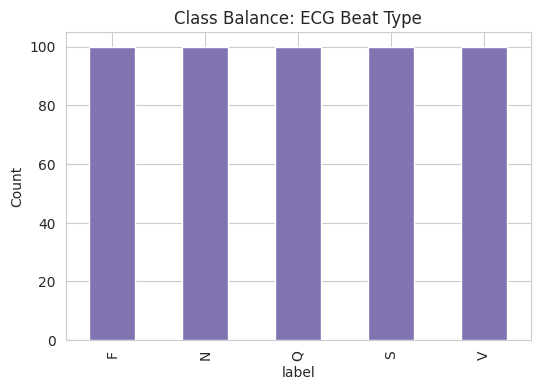

In [59]:

df_sig_labels = pd.Series(labels_clean, name="label")
plt.figure(figsize=(6, 4))
df_sig_labels.value_counts().sort_index().plot(kind="bar", color="#8172B2")
plt.title("Class Balance: ECG Beat Type")
plt.ylabel("Count")
plt.show()


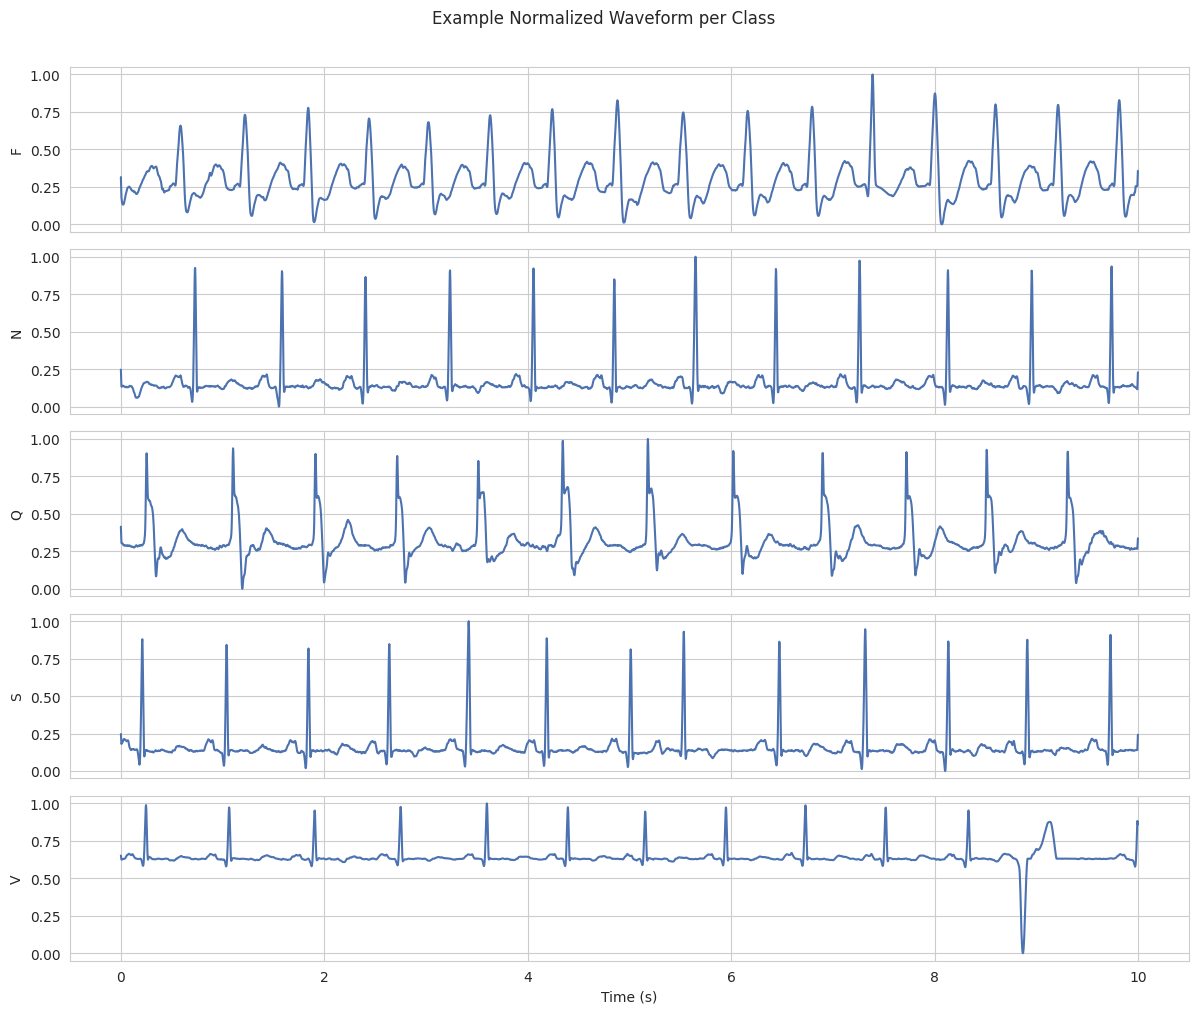

In [60]:

fig, axes = plt.subplots(5, 1, figsize=(12, 10), sharex=True)
for ax, cls in zip(axes, sorted(np.unique(labels_clean))):
    idx = np.where(labels_clean == cls)[0][0]
    ax.plot(np.arange(signals_norm.shape[1]) / 360, signals_norm[idx], color="#4C72B0")
    ax.set_ylabel(cls)
axes[-1].set_xlabel("Time (s)")
plt.suptitle("Example Normalized Waveform per Class", y=1.01)
plt.tight_layout()
plt.show()


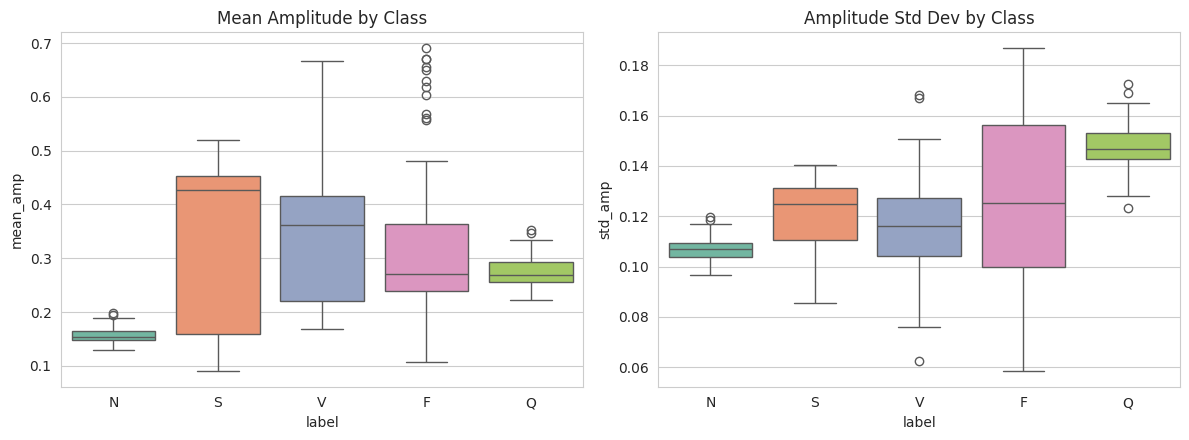

In [61]:

seg_mean = signals_norm.mean(axis=1)
seg_std2 = signals_norm.std(axis=1)
df_sig_eda = pd.DataFrame({"label": labels_clean, "mean_amp": seg_mean, "std_amp": seg_std2})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df_sig_eda, x="label", y="mean_amp", ax=axes[0], palette="Set2")
axes[0].set_title("Mean Amplitude by Class")
sns.boxplot(data=df_sig_eda, x="label", y="std_amp", ax=axes[1], palette="Set2")
axes[1].set_title("Amplitude Std Dev by Class")
plt.tight_layout()
plt.show()


## D.5 Hypothesis Testing

In [62]:

# ---- (1) One-way ANOVA ----
# H0: mean signal amplitude is equal across all 5 beat classes
# H1: at least one class differs
groups = [df_sig_eda.loc[df_sig_eda.label == c, "mean_amp"].values for c in sorted(df_sig_eda.label.unique())]
f_stat, anova_p = stats.f_oneway(*groups)
print(f"ANOVA (mean amplitude ~ beat class): F = {f_stat:.3f}, p = {anova_p:.2e}")
print("=> Reject H0: mean amplitude differs significantly across beat classes"
      if anova_p < 0.05 else "=> Fail to reject H0")


ANOVA (mean amplitude ~ beat class): F = 54.050, p = 8.49e-38
=> Reject H0: mean amplitude differs significantly across beat classes


In [63]:

# ---- (2) Two-sample t-test ----
# H0: mean amplitude std (signal variability) is equal for Normal (N) vs
#     Ventricular ectopic (V) beats
# H1: they differ
n_std = df_sig_eda.loc[df_sig_eda.label == "N", "std_amp"]
v_std = df_sig_eda.loc[df_sig_eda.label == "V", "std_amp"]
t_stat, t_p = stats.ttest_ind(n_std, v_std, equal_var=False)
print(f"T-TEST (amplitude variability: N vs V): t = {t_stat:.3f}, p = {t_p:.2e}")
print("=> Reject H0: N and V beats differ significantly in variability"
      if t_p < 0.05 else "=> Fail to reject H0")


T-TEST (amplitude variability: N vs V): t = -5.389, p = 3.95e-07
=> Reject H0: N and V beats differ significantly in variability


In [64]:

# ---- (3) Chi-square test of independence ----
# H0: "high variability" (top-tercile std_amp) is independent of beat class
# H1: high variability is associated with beat class
df_sig_eda["high_var"] = df_sig_eda["std_amp"] > df_sig_eda["std_amp"].quantile(2/3)
contingency = pd.crosstab(df_sig_eda["label"], df_sig_eda["high_var"])
chi2, chi_p, dof, expected = stats.chi2_contingency(contingency)
print(contingency)
print(f"\nCHI-SQUARE (high variability x beat class): chi2 = {chi2:.3f}, dof = {dof}, p = {chi_p:.2e}")
print("=> Reject H0: variability tier is associated with beat class"
      if chi_p < 0.05 else "=> Fail to reject H0")


high_var  False  True 
label                 
F            55     45
N           100      0
Q             8     92
S            85     15
V            85     15

CHI-SQUARE (high variability x beat class): chi2 = 241.013, dof = 4, p = 5.61e-51
=> Reject H0: variability tier is associated with beat class


## D.6 Feature Engineering — Selection, Extraction, Noise Removal, Augmentation

In [65]:

# --- Feature extraction: standard time-domain + frequency-domain
#     statistical features per segment (common lightweight ECG features) ---
def extract_signal_features(sig, fs=360):
    fft_vals = np.abs(np.fft.rfft(sig))
    fft_freqs = np.fft.rfftfreq(len(sig), d=1 / fs)
    dominant_freq = fft_freqs[np.argmax(fft_vals[1:]) + 1]  # skip DC component
    zero_crossings = np.sum(np.diff(np.sign(sig - sig.mean())) != 0)
    return {
        "mean": sig.mean(),
        "std": sig.std(),
        "skew": stats.skew(sig),
        "kurtosis": stats.kurtosis(sig),
        "zero_crossing_rate": zero_crossings / len(sig),
        "dominant_freq_hz": dominant_freq,
    }

sig_feat_rows = [extract_signal_features(s) for s in signals_norm]
df_sig_feats = pd.DataFrame(sig_feat_rows)
df_sig_feats["label"] = labels_clean
df_sig_feats.groupby("label").mean().round(3)


,mean,std,skew,kurtosis,zero_crossing_rate,dominant_freq_hz
label,,,,,,
F,0.320,0.127,1.996,10.606,0.022,2.816
N,0.156,0.107,5.231,29.772,0.023,3.709
Q,0.274,0.147,2.115,4.957,0.017,2.400
S,0.330,0.121,1.884,13.922,0.033,4.861
V,0.336,0.116,2.235,9.545,0.020,2.936


In [66]:

# --- Feature selection ---
from sklearn.feature_selection import SelectKBest, f_classif

feat_cols = ["mean", "std", "skew", "kurtosis", "zero_crossing_rate", "dominant_freq_hz"]
selector = SelectKBest(score_func=f_classif, k="all")
selector.fit(df_sig_feats[feat_cols], df_sig_feats["label"])
scores = pd.Series(selector.scores_, index=feat_cols).sort_values(ascending=False)
print("Feature scores (ANOVA F-value vs beat class):")
print(scores)


Feature scores (ANOVA F-value vs beat class):
kurtosis              231.861308
skew                   98.179330
std                    72.469700
mean                   54.050369
zero_crossing_rate     47.795296
dominant_freq_hz       47.788621
dtype: float64


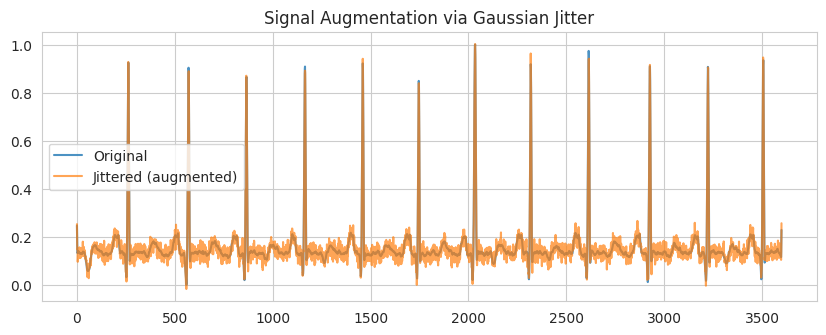

In [67]:

# --- Augmentation: label-preserving Gaussian-jitter augmentation, a
#     standard technique for expanding limited ECG training data ---
def jitter_augment(sig, sigma=0.02, rng=np.random.default_rng(RANDOM_STATE)):
    return sig + rng.normal(0, sigma, size=sig.shape)

sample = signals_norm[0]
jittered = jitter_augment(sample)

plt.figure(figsize=(10, 3.5))
plt.plot(sample, label="Original", alpha=0.8)
plt.plot(jittered, label="Jittered (augmented)", alpha=0.7)
plt.legend()
plt.title("Signal Augmentation via Gaussian Jitter")
plt.show()


## D.7 Why Signal Health Data Needs Extra Rigor

- **Physical noise sources** (baseline wander, muscle artifact, powerline
  interference) contaminate the true physiological signal and must be
  explicitly filtered before any feature extraction.
- **Corrupt/flatline segments** from lead disconnection look like valid
  rows in a CSV but carry no clinical information.
- **Severe class imbalance in real deployment** — rare arrhythmias (e.g.
  Fusion `F`, Unknown `Q`) are clinically the most important to catch but
  the least represented, making augmentation and careful evaluation critical.


---
# Summary — Why Healthcare Data Needs Extra Rigor Compared to Generic Datasets

Across all four modalities studied in this notebook, four recurring risks
show up in different disguises:

| Risk | Tabular (A) | Textual (B) | Image (C) | Signal (D) |
|---|---|---|---|---|
| **Missingness encoded as valid-looking values** | Zeros for Glucose/BMI/Insulin passed a naive null-check | Missing transcriptions had to be explicitly dropped | N/A (files either exist or are corrupt) | Flatline segments look like valid rows |
| **Class imbalance** | ~65/35 Outcome split | Surgery (~4x Radiology) dominates | Rare pathologies underrepresented | Rare arrhythmias (F, Q) are the minority yet most clinically important |
| **Privacy / PHI constraints** | Quasi-identifiers (Age + Pregnancies) | PHI embedded directly in free text, not a column | PHI hidden in EXIF/DICOM metadata | Generally de-identified by protocol, but linked timestamps can still re-identify |
| **Signal/measurement noise** | Outliers from mis-recorded values | Boilerplate/dictation artifacts | Sensor noise, acquisition variance | Baseline wander, muscle/powerline artifact |

Standard preprocessing pipelines built for generic (non-healthcare) data
assume nulls are marked as nulls, classes are balanced, no column is legally
sensitive, and measurement noise is negligible. Every one of those
assumptions failed at least once in this notebook — which is exactly why
healthcare data pipelines need modality-specific cleaning, explicit
hypothesis testing before modeling, and deliberate class-imbalance handling,
rather than a one-size-fits-all `dropna()` and `StandardScaler()`.
